## 1) The data

### Read in data

In [3]:
# Suppressing warnings to maintain clean output
import warnings
warnings.filterwarnings("ignore")

In [4]:
# Import packages
import sys
import os
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from random import sample

In [5]:
# Import our helper functions to resize images
from cv_helper_functions import *

In [7]:
# Retrieve directory where we will get the raw data from
parent_directory = os.path.abspath('')
print(parent_directory)
dataset_path = "data/"
print(dataset_path)

# Retrieve directory where we will get save processed data and features
path1="processed_data/"
features_path = os.path.join(path1,'features')
print(features_path)
os.makedirs(features_path, exist_ok=True)

h:\DR_Amira_Taco_trash_classification\New folder\update_Taco_classification
data/
processed_data/features


We load in an extract of the TACO data which is composed of:
* 1,500 raw images, stored in 15 sub-folders labelled "batch 1" to "batch 15".
* A json file called "annotations.json", organised in the convenient [COCO-Json](https://haobin-tan.netlify.app/ai/computer-vision/object-detection/coco-dataset-format/) format, widely used for object detection datasets.

In [8]:
# Read annotations file
import json
with open("{}/annotations.json".format(dataset_path), 'r') as f:
    annotdata = json.loads(f.read())
print( annotdata)

{'info': {'year': 2019, 'version': None, 'description': 'TACO', 'contributor': None, 'url': None, 'date_created': '2019-12-19T16:11:15.258399+00:00'}, 'images': [{'id': 0, 'width': 1537, 'height': 2049, 'file_name': 'batch_1/000006.jpg', 'license': None, 'flickr_url': 'https://farm66.staticflickr.com/65535/33978196618_e30a59e0a8_o.png', 'coco_url': None, 'date_captured': None, 'flickr_640_url': 'https://farm66.staticflickr.com/65535/33978196618_632623b4fc_z.jpg'}, {'id': 1, 'width': 1537, 'height': 2049, 'file_name': 'batch_1/000008.jpg', 'license': None, 'flickr_url': 'https://farm66.staticflickr.com/65535/47803331152_ee00755a2e_o.png', 'coco_url': None, 'date_captured': None, 'flickr_640_url': 'https://farm66.staticflickr.com/65535/47803331152_19beae025a_z.jpg'}, {'id': 2, 'width': 1537, 'height': 2049, 'file_name': 'batch_1/000010.jpg', 'license': None, 'flickr_url': 'https://farm66.staticflickr.com/65535/40888872753_08ffb24902_o.png', 'coco_url': None, 'date_captured': None, 'flick

### Show sample of images

Next, we will visualize a random sample of the images and annotations.
display images annotated in the COCO-Json format.

In [12]:
def display_images_with_coco_annotations(image_id_subset, figtitle, dataset_path, annotations, display_type='both', colors=None):
    """
    Function to display images with COCO annotations. Adapted from Dr. Sreenivas Bhattiprolu.

    Parameters:
    - image_id_subset (list): A list of image IDs to display.
    - figtitle (str): Title for the figure.
    - dataset_path (str): Path to the dataset directory.
    - annotations (dict): The dictionary containing COCO annotations data.
    - display_type (str, optional): Type of annotations to display. Options are 'bbox', 'seg', or 'both'. Default is 'both'.
    - colors (list, optional): List of colors for displaying annotations. Default is None.

    Returns:
    - None
    """
    # Subset of images that include the specified type
    subset_files = [os.path.join(dataset_path, img['file_name']) for img in annotations['images'] if img["id"] in image_id_subset]

    # Random subset of 6 images
    random.seed(0)
    image_paths = random.sample(subset_files, min(6,len(image_id_subset)))
    print( image_paths)
    fig, axs = plt.subplots(2, 3, figsize=(6, 4))

    for ax, img_path in zip(axs.ravel(), image_paths):
        # Load image using OpenCV and convert it from BGR to RGB color space
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image)
        ax.axis('off')  # Turn off the axes

        # Define a default color map if none is provided
        if colors is None:
            colors = plt.colormaps["tab10"]

        # Get image filename to match with annotations
        path_components = img_path.split("/")
        print(path_components)
        short_path = "{}/{}".format(path_components[-2],path_components[-1])
        print(short_path)
        img_id = next(item["id"] for item in annotations['images'] if item["file_name"] == short_path)

        # Filter annotations for the current image
        img_annotations = [ann for ann in annotations['annotations'] if ann['image_id'] == img_id]

        for ann in img_annotations:
            category_id = ann['category_id']
            color = colors(category_id % 10)

            # Display bounding box
            if display_type in ['bbox', 'both']:
                bbox = ann['bbox']
                rect = patches.Rectangle((bbox[0], bbox[1]), bbox[2], bbox[3], linewidth=1, edgecolor=color, facecolor='none')
                ax.add_patch(rect)

            # Display segmentation polygon
            if display_type in ['seg', 'both']:
                for seg in ann['segmentation']:
                    poly = [(seg[i], seg[i+1]) for i in range(0, len(seg), 2)]
                    polygon = patches.Polygon(poly, closed=True, edgecolor=color, fill=False)
                    ax.add_patch(polygon)

    plt.tight_layout(rect=[0, 0, 0.98, 0.98])
    fig.suptitle(figtitle)
    plt.show()

91        91
75        75
1264    1264
330      330
1349    1349
774      774
dtype: int64
['data/batch_2/000097.JPG', 'data/batch_8/000049.jpg', 'data/batch_1/000062.JPG', 'data/batch_1/000118.JPG', 'data/batch_12/000029.jpg', 'data/batch_7/000104.JPG']
['data', 'batch_2', '000097.JPG']
batch_2/000097.JPG
['data', 'batch_8', '000049.jpg']
batch_8/000049.jpg
['data', 'batch_1', '000062.JPG']
batch_1/000062.JPG
['data', 'batch_1', '000118.JPG']
batch_1/000118.JPG
['data', 'batch_12', '000029.jpg']
batch_12/000029.jpg
['data', 'batch_7', '000104.JPG']
batch_7/000104.JPG


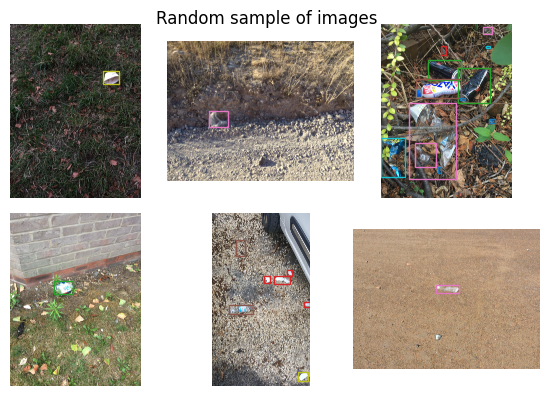

In [13]:
import matplotlib.patches as patches

# Randomly select 6 image IDs from the dataset
random_images = pd.Series([line["id"] for line in annotdata["images"]]).sample(6, random_state=1)
print(random_images)
# Display images along with COCO annotations
display_images_with_coco_annotations(
    image_id_subset=random_images,  # Subset of image IDs
    figtitle="Random sample of images",  # Title for the figure
    dataset_path=dataset_path,  # Path to the dataset
    annotations=annotdata,  # COCO annotations
    display_type='bbox'  # Display type for annotations
)

From our snapshot of the data above, we can see that the images will need some processing before we can apply our machine learning models:

* Often, the object is very small in relation to the image background. This is particularly the case for small objects, like cigarette butts.
* Some objects appear 'distorted' - for example, they are bent or broken. This appears to be more common among objects photographed outdoors and those made of soft materials (like plastic film or cardboard). These distortions might make the images more difficult to classify.
* Object masks (the segmentations, such as the contour of a plastic bottle) are not provided as stand-alone images, so we will need to create them for each annotation.

## 2) Exploratory data analysis

### Missing data and duplicates

#### Image dataset

First, we conduct some exploratory data analysis at the image level. We start by saving the images data into a pandas DataFrame.First, we conduct some exploratory data analysis at the image level. We start by saving the images data into a pandas DataFrame. The images file contains one row per image in the dataset, for a total of 1,500 images. It contains:

* An image id
* Image width
* Image height
* File name (and its batch)
* Type of license

All information on the date captured is missing, and there are no duplicates in the images dataset.

In [14]:
# Preview image data
df=pd.DataFrame(annotdata["images"])
df.tail()

,id,width,height,file_name,license,flickr_url,coco_url,date_captured,flickr_640_url
1495,1495,1824,4000,batch_9/000095.jpg,CC,https://farm66.staticflickr.com/65535/48701319...,None,None,https://farm66.staticflickr.com/65535/48701319...
1496,1496,1824,4000,batch_9/000096.jpg,CC,https://farm66.staticflickr.com/65535/48701319...,None,None,https://farm66.staticflickr.com/65535/48701319...
1497,1497,4000,1824,batch_9/000097.jpg,CC,https://farm66.staticflickr.com/65535/48694319...,None,None,https://farm66.staticflickr.com/65535/48694319...
1498,1498,1824,4000,batch_9/000098.jpg,CC,https://farm66.staticflickr.com/65535/48693804...,None,None,https://farm66.staticflickr.com/65535/48693804...
1499,1499,1824,4000,batch_9/000099.jpg,CC,https://farm66.staticflickr.com/65535/48701147...,None,None,https://farm66.staticflickr.com/65535/48701147...


In [15]:
df.shape,df.columns

((1500, 9),
 Index(['id', 'width', 'height', 'file_name', 'license', 'flickr_url',
        'coco_url', 'date_captured', 'flickr_640_url'],
       dtype='object'))

In [16]:
#check null values and duplicate
df.isnull().sum()


id                   0
width                0
height               0
file_name            0
license            715
flickr_url           0
coco_url          1500
date_captured     1500
flickr_640_url     466
dtype: int64

<Axes: >

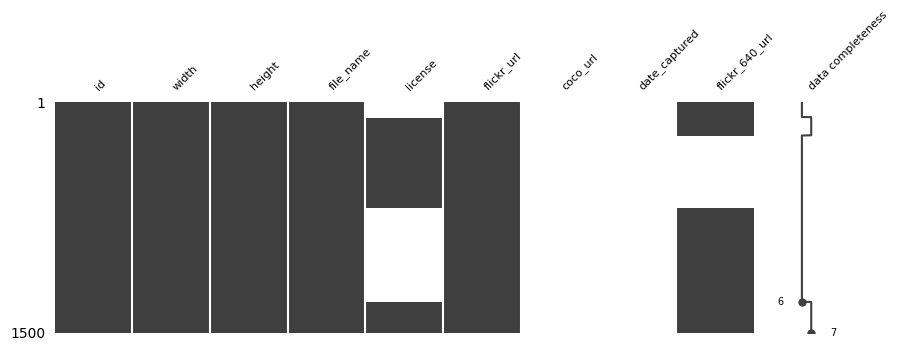

In [17]:
# Check missing data
import missingno as msno
msno.matrix(pd.DataFrame(annotdata["images"]), fontsize=8,labels=True, figsize=(10,3))

#### Annotations dataset

The annotations file is where we will find most of the relevant information for our analysis. This is where each annotation (e.g. the contour of a plastic bottle and the 'plastic bottle' tag) is stored. There are 4,784 annotations in this version of the dataset.

This dataset includes:

* The annotation id (id)
* Its corresponding image id (image_id)
* The category id (category_id), i.e. whether the annotation is a bottle, a pizza box or other.
* The segmentation itself ('segmentation'), with values indicating which pixels are within the segment (also called the 'mask').
* The annotation area ('area').
* The bounding box for the annotation ('bbox'), i.e. the rectangular area containing the edges of the annotation. This is a list of four numbers representing the bounding box of the annotated object in the format [x, y, width, height], where (x, y) is the top-left corner of the bounding box ([more information here on bounding boxes in COCO](https://medium.com/@manuktiwary/coco-format-what-and-how-5c7d22cf5301)).

In [18]:
# Preview data
df_annotate=pd.DataFrame(annotdata["annotations"])
df_annotate.tail()

,id,image_id,category_id,segmentation,area,bbox,iscrowd
4779,4779,1498,16,"[[386, 1557, 635, 1567, 986, 1556, 1178, 1550,...",503246.94850,"[228.7143, 1550.0476, 1007.9998999999999, 578....",0
4780,4780,1498,7,"[[1057, 1824, 1041, 1793, 1042, 1758, 1062, 17...",14494.50000,"[1041.3334, 1721.7142, 141.0, 138.0]",0
4781,4781,1499,39,"[[1368, 1775, 1099, 1331, 862, 1494, 1099, 1944]]",154954.10875,"[862.0274, 1331.25, 505.97260000000006, 612.5]",0
4782,4782,1499,14,"[[1096, 1996, 1121, 2069, 1134, 2127, 1177, 22...",28675.00000,"[966.0, 1996.0, 211.0, 336.0]",0
4783,4783,1499,6,"[[1125, 1937, 1135, 2012, 1194, 2013, 1221, 20...",68589.50000,"[1125.0, 1858.0, 234.0, 510.0]",0


In [19]:
df_annotate.isnull().sum()

id              0
image_id        0
category_id     0
segmentation    0
area            0
bbox            0
iscrowd         0
dtype: int64

In [20]:
df_annotate.shape ,df_annotate.columns

((4784, 7),
 Index(['id', 'image_id', 'category_id', 'segmentation', 'area', 'bbox',
        'iscrowd'],
       dtype='object'))

In [35]:
# Save to DataFrame
annot_df = pd.DataFrame(annotdata["annotations"]).drop(["area"], axis=1)
annot_df.count()

id              4784
image_id        4784
category_id     4784
segmentation    4784
bbox            4784
iscrowd         4784
dtype: int64

We drop the duplicated annotation (which is tagged with two different categories).

In [36]:
# Drop duplicates
annot_df.drop_duplicates(subset=['id'], keep='first', inplace=True)
annot_df.count()

id              4782
image_id        4782
category_id     4782
segmentation    4782
bbox            4782
iscrowd         4782
dtype: int64

Then, we merge in the annotation category labels so that we can conveniently see to which category and supercategory each annotation belongs.

In [37]:
cat=pd.DataFrame(annotdata["categories"])
cat.head(10)

,supercategory,id,name
0,Aluminium foil,0,Aluminium foil
1,Battery,1,Battery
2,Blister pack,2,Aluminium blister pack
3,Blister pack,3,Carded blister pack
4,Bottle,4,Other plastic bottle
5,Bottle,5,Clear plastic bottle
6,Bottle,6,Glass bottle
7,Bottle cap,7,Plastic bottle cap
8,Bottle cap,8,Metal bottle cap
9,Broken glass,9,Broken glass


In [38]:
# Merge annotations to image data

categories_dict = pd.DataFrame(annotdata["categories"]).loc[:,["id","name","supercategory"]]
categories_dict.head(20)

,id,name,supercategory
0,0,Aluminium foil,Aluminium foil
1,1,Battery,Battery
2,2,Aluminium blister pack,Blister pack
3,3,Carded blister pack,Blister pack
4,4,Other plastic bottle,Bottle
5,5,Clear plastic bottle,Bottle
6,6,Glass bottle,Bottle
7,7,Plastic bottle cap,Bottle cap
8,8,Metal bottle cap,Bottle cap
9,9,Broken glass,Broken glass


In [39]:
categories_dict.rename({'id': 'category_id', 'name': 'category'}, axis=1, inplace=True)
#print(categories_dict)
#after merging
annot_df1 = annot_df.merge(categories_dict, on='category_id', how='left').copy()
annot_df1.head()

,id,image_id,category_id,segmentation,bbox,iscrowd,category,supercategory
0,1,0,6,"[[561.0, 1238.0, 568.0, 1201.0, 567.0, 1175.0,...","[517.0, 127.0, 447.0, 1322.0]",0,Glass bottle,Bottle
1,2,1,18,"[[928.0, 1876.0, 938.0, 1856.0, 968.0, 1826.0,...","[1.0, 457.0, 1429.0, 1519.0]",0,Meal carton,Carton
2,3,1,14,"[[617.0, 383.0, 703.0, 437.0, 713.0, 456.0, 72...","[531.0, 292.0, 1006.0, 672.0]",0,Other carton,Carton
3,4,2,5,"[[670.0, 993.0, 679.0, 998.0, 684.0, 1001.0, 6...","[632.0, 987.0, 500.0, 374.0]",0,Clear plastic bottle,Bottle
4,5,2,7,"[[647.0, 1028.0, 650.0, 1022.0, 653.0, 1016.0,...","[632.0, 989.0, 44.0, 51.0]",0,Plastic bottle cap,Bottle cap


In [40]:
annot_df1.columns

Index(['id', 'image_id', 'category_id', 'segmentation', 'bbox', 'iscrowd',
       'category', 'supercategory'],
      dtype='object')

We would like to visualize the most common supercategories. The most common supercategory is **plastic bag and wrapper**, which contains many different types of objects such as plastic film, carrier bags and crisp packets. The second most common supercategory are **cigarettes**, followed by **unlabelled litter**. Some supercategories, like shoes or batteries, are very rare.

In [41]:
counts_by_cat1 = pd.DataFrame(annot_df1.groupby(["supercategory","category"]).size(),columns=["count"]).reset_index()
counts_by_cat1.head(10)


,supercategory,category,count
0,Aluminium foil,Aluminium foil,62
1,Battery,Battery,2
2,Blister pack,Aluminium blister pack,6
3,Blister pack,Carded blister pack,1
4,Bottle,Clear plastic bottle,284
5,Bottle,Glass bottle,104
6,Bottle,Other plastic bottle,50
7,Bottle cap,Metal bottle cap,80
8,Bottle cap,Plastic bottle cap,209
9,Broken glass,Broken glass,138


In [42]:
counts_by_cat1["supercount"] = counts_by_cat1.groupby("supercategory")["count"].transform('sum')
counts_by_cat1.head(60)

,supercategory,category,count,supercount
0,Aluminium foil,Aluminium foil,62,62
1,Battery,Battery,2,2
2,Blister pack,Aluminium blister pack,6,7
3,Blister pack,Carded blister pack,1,7
4,Bottle,Clear plastic bottle,284,438
5,Bottle,Glass bottle,104,438
6,Bottle,Other plastic bottle,50,438
7,Bottle cap,Metal bottle cap,80,289
8,Bottle cap,Plastic bottle cap,209,289
9,Broken glass,Broken glass,138,138


In [43]:
counts_by_cat1 = counts_by_cat1.sort_values(by=['supercount','count'], ascending=False)
counts_by_cat1.head(30)

,supercategory,category,count,supercount
39,Plastic bag & wrapper,Plastic film,451,850
38,Plastic bag & wrapper,Other plastic wrapper,260,850
41,Plastic bag & wrapper,Single-use carrier bag,61,850
36,Plastic bag & wrapper,Crisp packet,39,850
37,Plastic bag & wrapper,Garbage bag,31,850
42,Plastic bag & wrapper,Six pack rings,5,850
40,Plastic bag & wrapper,Polypropylene bag,3,850
20,Cigarette,Cigarette,667,667
58,Unlabeled litter,Unlabeled litter,516,516
4,Bottle,Clear plastic bottle,284,438


In [44]:
unique_supercategories1 = counts_by_cat1['supercategory'].unique()
unique_supercategories1

array(['Plastic bag & wrapper', 'Cigarette', 'Unlabeled litter', 'Bottle',
       'Bottle cap', 'Other plastic', 'Can', 'Carton', 'Cup', 'Straw',
       'Paper', 'Broken glass', 'Styrofoam piece', 'Pop tab', 'Lid',
       'Plastic container', 'Aluminium foil', 'Plastic utensils',
       'Rope & strings', 'Paper bag', 'Scrap metal', 'Food waste', 'Shoe',
       'Squeezable tube', 'Blister pack', 'Glass jar', 'Plastic glooves',
       'Battery'], dtype=object)

In [45]:
zip(unique_supercategories1, sns.color_palette("tab10", len(unique_supercategories1)))

In [46]:
supercategory_colors1 = dict(zip(unique_supercategories1, sns.color_palette("tab10", len(unique_supercategories1))))
supercategory_colors1

{'Plastic bag & wrapper': (0.12156862745098039,
  0.4666666666666667,
  0.7058823529411765),
 'Cigarette': (1.0, 0.4980392156862745, 0.054901960784313725),
 'Unlabeled litter': (0.17254901960784313,
  0.6274509803921569,
  0.17254901960784313),
 'Bottle': (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 'Bottle cap': (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 'Other plastic': (0.5490196078431373,
  0.33725490196078434,
  0.29411764705882354),
 'Can': (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 'Carton': (0.4980392156862745, 0.4980392156862745, 0.4980392156862745),
 'Cup': (0.7372549019607844, 0.7411764705882353, 0.13333333333333333),
 'Straw': (0.09019607843137255, 0.7450980392156863, 0.8117647058823529),
 'Paper': (0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 'Broken glass': (1.0, 0.4980392156862745, 0.054901960784313725),
 'Styrofoam piece': (0.17254901960784313,
  0.6274509803921569,
  0.17254901960784313),
 'Pop

In [47]:
counts_by_cat1['color'] = counts_by_cat1['supercategory'].map(supercategory_colors1)
counts_by_cat1.head()

,supercategory,category,count,supercount,color
39,Plastic bag & wrapper,Plastic film,451,850,"(0.12156862745098039, 0.4666666666666667, 0.70..."
38,Plastic bag & wrapper,Other plastic wrapper,260,850,"(0.12156862745098039, 0.4666666666666667, 0.70..."
41,Plastic bag & wrapper,Single-use carrier bag,61,850,"(0.12156862745098039, 0.4666666666666667, 0.70..."
36,Plastic bag & wrapper,Crisp packet,39,850,"(0.12156862745098039, 0.4666666666666667, 0.70..."
37,Plastic bag & wrapper,Garbage bag,31,850,"(0.12156862745098039, 0.4666666666666667, 0.70..."


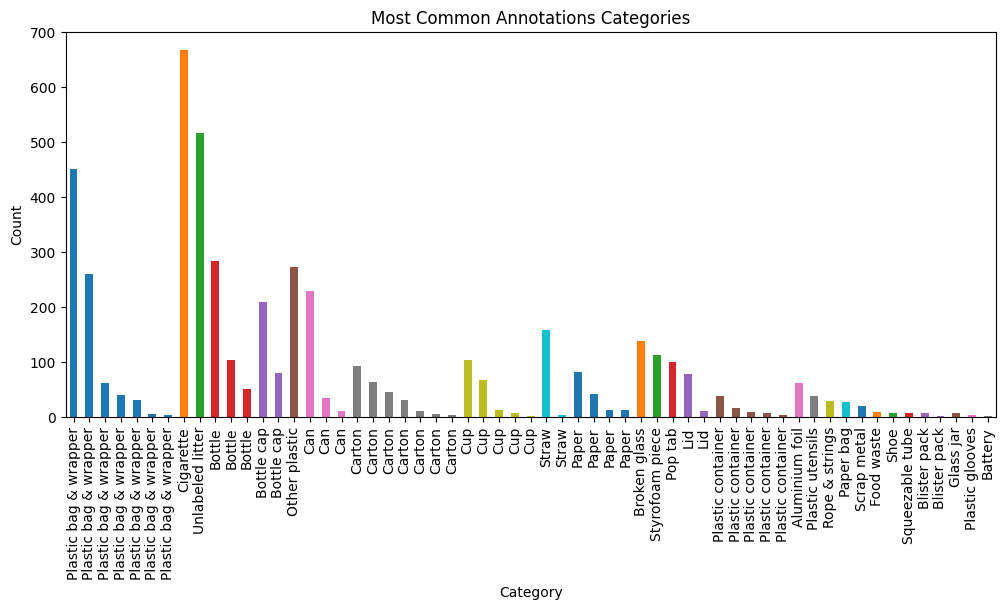

In [48]:
# Create the bar chart with colormap
plt.figure(figsize=(12, 5))
counts_by_cat1.set_index("supercategory")["count"].plot(kind="bar", color=counts_by_cat1.color)

# Remove legend (optional)
plt.legend().remove()

# Rotate x-axis labels
plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Most Common Annotations Categories")

plt.show()

### Create class labels for classification problems

Our classification task will try to distinguish between five types of objects:
* Bottles
* Cartons
* Cups
* Cans
* Plastic film

We create the string variable 'c1_label' containing the object labels according to the above taxonomy, and its numerical version 'c1_numlabel'.

In [49]:
# Create the c1 "label" variable
annot_df1["c1_label"] = np.nan
annot_df1.loc[annot_df1["supercategory"]=="Bottle","c1_label"] = "Bottle"
annot_df1.loc[annot_df1["supercategory"]=="Carton","c1_label"] = "Carton"
annot_df1.loc[annot_df1["supercategory"]=="Cup","c1_label"] = "Cup"
annot_df1.loc[annot_df1["category"].isin(["Drink can","Food can"]),"c1_label"] = "Can"
annot_df1.loc[annot_df1["category"].isin(["Plastic film"]),"c1_label"] = "Plastic film"



In [30]:
annot_df1.head()

,id,image_id,category_id,segmentation,bbox,iscrowd,category,supercategory,c1_label
0,1,0,6,"[[561.0, 1238.0, 568.0, 1201.0, 567.0, 1175.0,...","[517.0, 127.0, 447.0, 1322.0]",0,Glass bottle,Bottle,Bottle
1,2,1,18,"[[928.0, 1876.0, 938.0, 1856.0, 968.0, 1826.0,...","[1.0, 457.0, 1429.0, 1519.0]",0,Meal carton,Carton,Carton
2,3,1,14,"[[617.0, 383.0, 703.0, 437.0, 713.0, 456.0, 72...","[531.0, 292.0, 1006.0, 672.0]",0,Other carton,Carton,Carton
3,4,2,5,"[[670.0, 993.0, 679.0, 998.0, 684.0, 1001.0, 6...","[632.0, 987.0, 500.0, 374.0]",0,Clear plastic bottle,Bottle,Bottle
4,5,2,7,"[[647.0, 1028.0, 650.0, 1022.0, 653.0, 1016.0,...","[632.0, 989.0, 44.0, 51.0]",0,Plastic bottle cap,Bottle cap,NaN


In [50]:
# Create the numerical "label" variable
annot_df1["c1_numlabel"] = annot_df1['c1_label'].replace(list(annot_df1['c1_label'].value_counts().index),list(range(1,6)), inplace=False)

In [51]:
annot_df1.head(10)

,id,image_id,category_id,segmentation,bbox,iscrowd,category,supercategory,c1_label,c1_numlabel
0,1,0,6,"[[561.0, 1238.0, 568.0, 1201.0, 567.0, 1175.0,...","[517.0, 127.0, 447.0, 1322.0]",0,Glass bottle,Bottle,Bottle,2.0
1,2,1,18,"[[928.0, 1876.0, 938.0, 1856.0, 968.0, 1826.0,...","[1.0, 457.0, 1429.0, 1519.0]",0,Meal carton,Carton,Carton,3.0
2,3,1,14,"[[617.0, 383.0, 703.0, 437.0, 713.0, 456.0, 72...","[531.0, 292.0, 1006.0, 672.0]",0,Other carton,Carton,Carton,3.0
3,4,2,5,"[[670.0, 993.0, 679.0, 998.0, 684.0, 1001.0, 6...","[632.0, 987.0, 500.0, 374.0]",0,Clear plastic bottle,Bottle,Bottle,2.0
4,5,2,7,"[[647.0, 1028.0, 650.0, 1022.0, 653.0, 1016.0,...","[632.0, 989.0, 44.0, 51.0]",0,Plastic bottle cap,Bottle cap,NaN,NaN
5,6,3,5,"[[354.0, 1268.0, 351.0, 1252.0, 347.0, 1237.0,...","[209.0, 920.0, 454.0, 562.0]",0,Clear plastic bottle,Bottle,Bottle,2.0
6,7,3,5,"[[1239.0, 841.0, 1247.0, 842.0, 1252.0, 835.0,...","[1212.0, 822.0, 179.0, 446.0]",0,Clear plastic bottle,Bottle,Bottle,2.0
7,8,3,7,"[[643.0, 1453.0, 649.0, 1445.0, 653.0, 1442.0,...","[634.0, 1442.0, 29.0, 39.0]",0,Plastic bottle cap,Bottle cap,NaN,NaN
8,9,3,12,"[[730.0, 852.0, 700.0, 810.0, 686.0, 789.0, 68...","[589.0, 548.0, 341.0, 405.0]",0,Drink can,Can,Can,4.0
9,10,4,12,"[[1032.0, 1170.0, 1040.0, 1144.0, 1046.0, 1125...","[556.0, 944.0, 490.0, 336.0]",0,Drink can,Can,Can,4.0


## 3) Save data

Having merged the information on images properties (e.g. size and bounding box coverage), background annotations and class labels to our annotations dataframe, we can save this DataFrame to a '.csv' file locally.

In [52]:
# Save data
annot_df1.to_csv("{}/{}".format(features_path,"processed-annotations-data.csv"))

## 1) Load clean data

In this second notebook, we start by importing the original annotations dataset (*annotdata*) and the 'clean' version we produced that includes additional variables used in exploratory data analysis (*annot_df*).

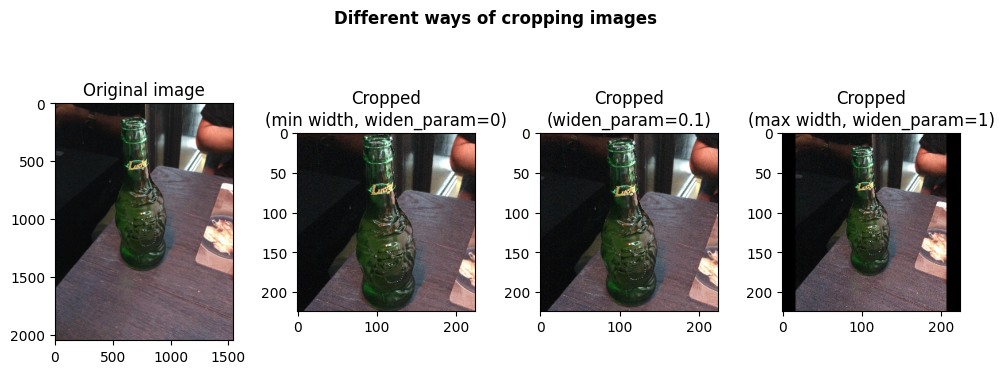

In [59]:
# Create a figure with 1 row and 4 columns
fig, axes = plt.subplots(1, 4, figsize=(10, 4))

# Flatten the axes array
axes = axes.flatten()

# Display original image
axes[0].imshow(show_annotation_image(annotation_id=1, annotations=annotdata, dataset_path=dataset_path))
axes[0].set_title("Original image")

# Display cropped image with minimum width
axes[1].imshow(try_square_crop(annotation_id=1, annotations=annotdata, widen_param=0, newsize=224, dataset_path=dataset_path))
axes[1].set_title("Cropped\n(min width, widen_param=0)")

# Display cropped image with slight widening
axes[2].imshow(try_square_crop(annotation_id=1, annotations=annotdata, widen_param=0.1, newsize=224, dataset_path=dataset_path))
axes[2].set_title("Cropped\n(widen_param=0.1)")

# Display cropped image with maximum width
axes[3].imshow(try_square_crop(annotation_id=1, annotations=annotdata, widen_param=1, newsize=224, dataset_path=dataset_path))
axes[3].set_title("Cropped\n(max width, widen_param=1)")

# Add title to the figure
fig.suptitle("Different ways of cropping images", fontsize=12, fontweight="bold")

# Adjust layout to fit the title properly
plt.tight_layout(rect=[0, 0, 0.98, 0.98])

# Show the plot
plt.show()

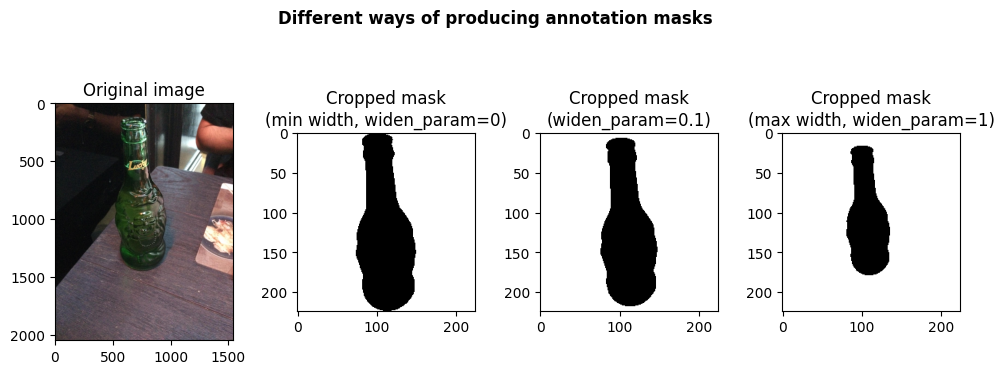

In [60]:
# Create a figure with 1 row and 4 columns
fig, axes = plt.subplots(1, 4, figsize=(10, 4))

# Flatten the axes array
axes = axes.flatten()

# Display original image with grayscale colormap
axes[0].imshow(show_annotation_image(annotation_id=1, annotations=annotdata, dataset_path=dataset_path), cmap="Greys")
axes[0].set_title("Original image")

# Display cropped mask image with minimum width
axes[1].imshow(mask_and_square_crop(annotation_id=1, annotations=annotdata, widen_param=0, newsize=224, dataset_path=dataset_path), cmap="Greys")
axes[1].set_title("Cropped mask\n(min width, widen_param=0)")

# Display cropped mask image with slight widening
axes[2].imshow(mask_and_square_crop(annotation_id=1, annotations=annotdata, widen_param=0.1, newsize=224, dataset_path=dataset_path), cmap="Greys")
axes[2].set_title("Cropped mask\n(widen_param=0.1)")

# Display cropped mask image with maximum width
axes[3].imshow(mask_and_square_crop(annotation_id=1, annotations=annotdata, widen_param=1, newsize=224, dataset_path=dataset_path), cmap="Greys")
axes[3].set_title("Cropped mask\n(max width, widen_param=1)")

# Add title to the figure
fig.suptitle("Different ways of producing annotation masks", fontsize=12, fontweight="bold")

# Adjust layout to fit the title properly
plt.tight_layout(rect=[0, 0, 0.98, 0.98])

# Show the plot
plt.show()

## 2) Functions to process images for machine learning models

We have written three functions that will process our images in preparation for our machine learning models.:

- **Show annotation**: The first function simply takes an _annotation id_ and returns the image containing this annotation, without any additional transformations.
- **Crop image around annotation**: The purpose of the second function is to crop the image around the annotation (with id _annotation_id_), thus removing background elements (such as a road or a landscape). It should be easier to classify images if objects are in the centre of the image and we and remove other objects around it.
- **Create annotation mask**: The third function creates a "black and white" image showing the contour of each annotation.

### Crop image around annotation

The first step is to load the image containing the annotation of interest. Then, we recover the annotation bounding box from the annotations COCO-Json file and compute the bounding box centroid.

Next, we draw a square around this centroid and control the size of the square side with the parameter **widen_param**:

- If **widen_param** is 0, its smallest allowed value, then we will draw the smallest square possible around the annotation bounding box while retaining the entire bounding box.
- If **widen_param** is 1, its allowed largest value, then the side of the square will be equal to the side of the original image (either the width or the height, whichever is highest). Occasionally, the boundaries of this square fall outside the image itself. For example, if the object was near a corner. In that case, the cropped area is no longer square and will be rectangular. If this is the case, we add black borders around the rectangle to make it square.

The side of the final square can be controlled with the **newsize** parameter.

We demonstrate how this function works by showing an example with three values of the **widen_param** parameter.

### Create image mask

The function below has two steps:

* It converts the annotation into a new image (_a mask_) showing the contours of the annotation.
* Then, it crops the resulting mask image in exactly the same way as the function described above (try_square_crop).

By using these two functions, each processed image will have its equivalent mask image that exactly mirrors the original image in terms of where the object is located.

We demsonstrate how this function works below, using the same source image.

## 3) Selecting samples for classification models

### Selecting samples for classification model

Based on our exploratory analysis, we restrict our classification task to the following objects:

* Bottles
* Cartons
* Cups
* Cans
* Plastic film

This results in 1,561 total usable annotations. The variables useful for classification, including the labels and image and annotation id's are stored in DataFrame 'annot_df_c1'.

In [ ]:
# Read clean annotations file
annot_df_2 = pd.read_csv("{}/{}".format(features_path,"processed-annotations-data.csv"))

In [62]:
# Select a subset of the data
annot_df_c1 = annot_df_2.dropna(subset=['c1_label'], inplace=False)
annot_df_c1.reset_index(drop=True, inplace=True)
annot_df_c1.shape

(1561, 11)

In [63]:
# Only keep the relevant columns
annot_df_c1 = annot_df_c1[["id","image_id","category_id","c1_numlabel","c1_label"]].copy()
annot_df_c1.head(10)

,id,image_id,category_id,c1_numlabel,c1_label
0,1,0,6,2.0,Bottle
1,2,1,18,3.0,Carton
2,3,1,14,3.0,Carton
3,4,2,5,2.0,Bottle
4,6,3,5,2.0,Bottle
5,7,3,5,2.0,Bottle
6,9,3,12,4.0,Can
7,10,4,12,4.0,Can
8,13,5,4,2.0,Bottle
9,18,7,5,2.0,Bottle


Some of our 1,561 annotations are in fact in the same image. For example, 340 images contain two different annotations. However, if we use our image cropping approach around each annotation bounding box, we can treat each of these as separate images.

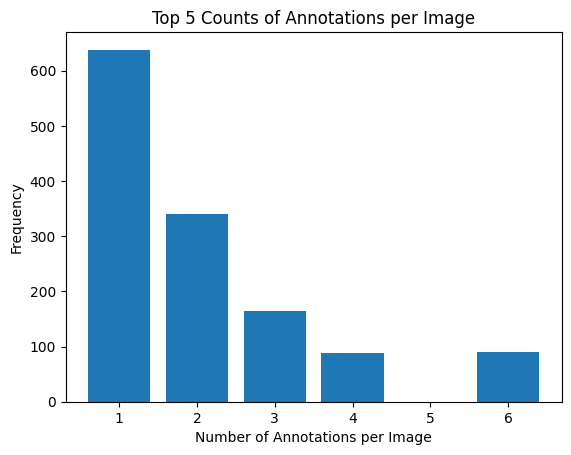

In [64]:
# Compute annotations by image
annot_df_c1["annotations_by_image"] = annot_df_c1.groupby('image_id')['id'].transform('count')

# Get the top 5 value counts
top_counts = annot_df_c1["annotations_by_image"].value_counts()[:5]

# Plotting the bar graph
plt.bar(top_counts.index, top_counts.values)
plt.xlabel('Number of Annotations per Image')
plt.ylabel('Frequency')
plt.title('Top 5 Counts of Annotations per Image')
plt.show()

For this classification problem, we choose a widen_param of 0.05 - this results in a close crop around the annotation bounding box but retains a small amount of backround elements as shown below.

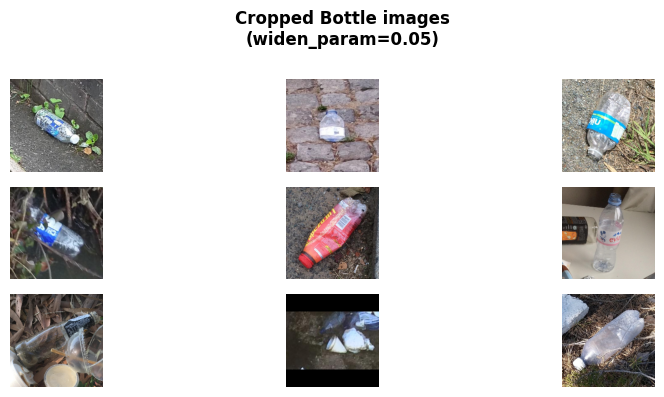

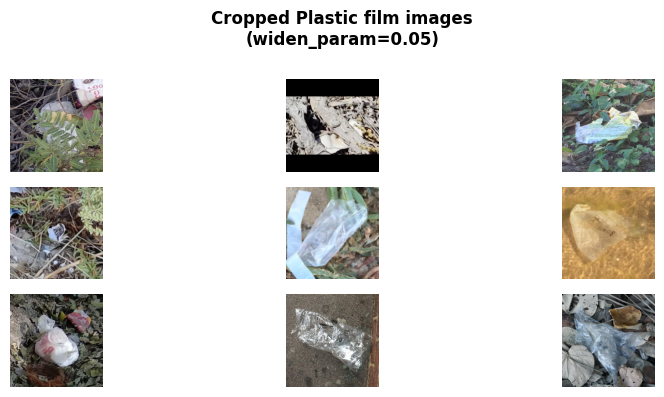

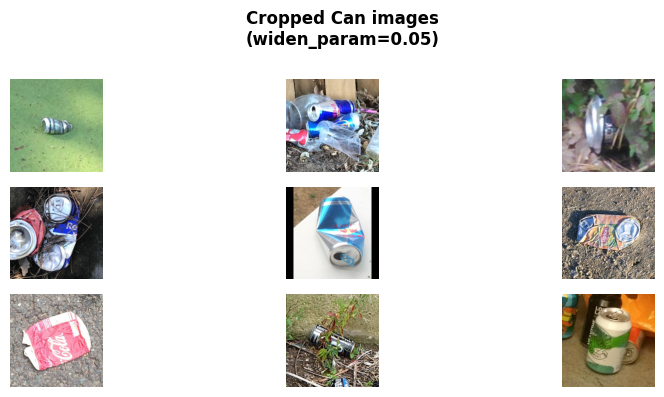

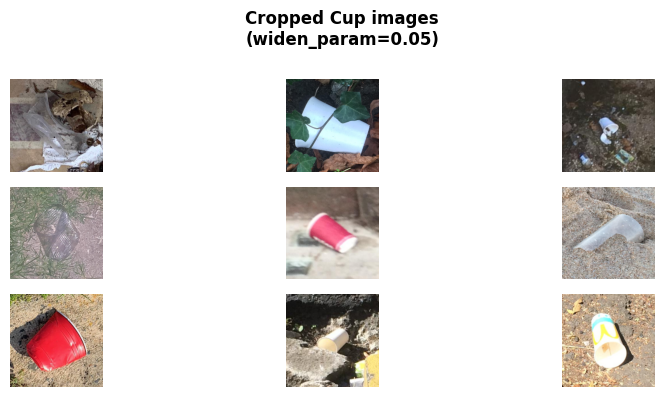

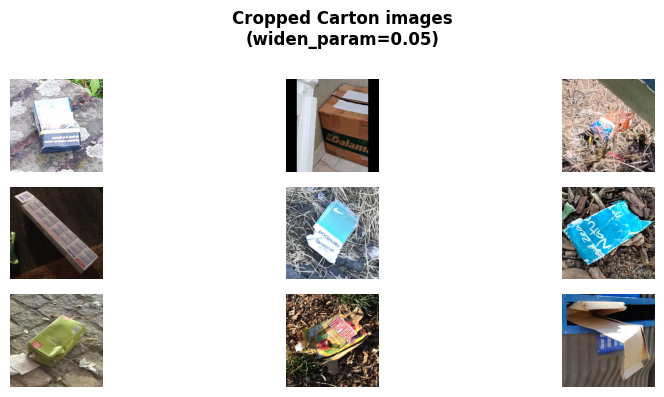

In [65]:
def plot_cropped_images(label, annotations_df, annotdata, widen_param=0.05, newsize=224, dataset_path=None):
    # Select samples for the given label
    annotations_samples = sample(list(annotations_df.loc[annotations_df.c1_label == label, "id"]), 9)
    
    # Create subplots
    fig, axes = plt.subplots(3, 3, figsize=(10, 4))
    
    # Plot cropped images
    for (annotindex, ax) in zip(annotations_samples, axes.flatten()):
        ax.imshow(try_square_crop(annotindex, annotations=annotdata, widen_param=widen_param, newsize=newsize, dataset_path=dataset_path))
        ax.set_axis_off()
    
    # Set title and adjust layout
    fig.suptitle(f"Cropped {label} images\n(widen_param={widen_param})", fontsize=12, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 0.98, 0.98])
    plt.show()

# Plot cropped images for each category
categories = ["Bottle", "Plastic film", "Can", "Cup", "Carton"]
for category in categories:
    plot_cropped_images(category, annot_df_c1, annotdata, widen_param=0.05, newsize=224, dataset_path=dataset_path)


### Selecting samples for image segmentation analysis

For our image segmentation task, we will focus on images of bottles. However, we will only work with images that have a single bottle. This leaves us with 248 images.

In [66]:
# Filter annotations DataFrame to include only annotations related to the "Bottle" supercategory
annot_df_s1 = annot_df_2.loc[annot_df_2["supercategory"].isin(["Bottle"]), :]

# Extract relevant columns and create a copy
annot_df_s1 = annot_df_s1[["id", "image_id", "category_id"]].copy()

# Count the number of annotations per image and create a new column
annot_df_s1["annotations_by_image"] = annot_df_s1.groupby('image_id')['id'].transform('count')

# Keep only images with one annotation
annot_df_s1 = annot_df_s1.loc[annot_df_s1.annotations_by_image == 1, :].copy()

# Reset index and update DataFrame shape
annot_df_s1.reset_index(drop=True, inplace=True)
annot_df_s1.shape

(248, 4)

In [67]:
annot_df_s1.head()

,id,image_id,category_id,annotations_by_image
0,1,0,6,1
1,4,2,5,1
2,13,5,4,1
3,18,7,5,1
4,20,8,5,1


### Saving classification labels

In [68]:
# Save classification labels

np.savez("{}/{}".format(features_path,"classification-labels.npz"), c1=annot_df_c1, s1=annot_df_s1,
         c1_colnames=annot_df_c1.columns, s1_colnames=annot_df_s1.columns)

## 4) Process images for classification models

Finally, we process the images we will use in our classification and segmentation tasks. As a reminder:

* For our classification tasks, this means resizing and cropping the images in a square around the annotation bounding box and, if necessary, adding a black border.
* On top of the above, for our segmentation task, we also need to produce image masks that mirror exactly the same transformations applied to the original images.

We do this for three values of the *widen_param* parameter, so we can perform sensitivity analyses in our machine learning tasks if needed.

In [69]:
# Change the value of generate_cropped_images to True if you wish to generate the cropped images
# This only needs to be done once, as it can be time consuming
generate_cropped_images = True

In [70]:
# Only run if generate_cropped_images is True
generate_cropped_images = True
if generate_cropped_images:
    for width in [0.05]:
        # Generate images for task C1, and store as a 4-dimensional numpy array
        c1_data = [try_square_crop(idx, annotations=annotdata, widen_param=width, newsize=224, dataset_path=dataset_path) for idx in list(annot_df_c1.id)]
        c1_data = np.stack(c1_data, axis=0)

        # Find the locations (indices) of images for task S1 within the set prepared for task C1 (S1 is also a subset of C1)
        # And store those images is a separate 4-dimensional numpy array
        s1_locations_in_c1 = annot_df_s1["id"].map(lambda x: annot_df_c1.index[annot_df_c1.id==x][0])
        s1_data = c1_data[s1_locations_in_c1,:,:,:]

        # Create binary image masks for images used in task S1
        # And store those images in a separate 4-dimensional numpy array
        s1_masks = [mask_and_square_crop(idx, annotations=annotdata, widen_param=width, newsize=224, dataset_path=dataset_path) for idx in list(annot_df_s1.id)]
        s1_masks = np.stack(s1_masks, axis=0)

        # Create folder to store the transformed images and masks
        destination = "{}/{}".format(features_path,"widen_param_{}".format(width))
        os.makedirs(destination, exist_ok=True)

        # Save data
        np.savez("{}/{}".format(destination,"classification-images.npz"), c1=c1_data, s1=s1_data, s1_masks=s1_masks)

# Classifying objects

In this notebook, we will use machine learning models to classify images of:
    
* Bottles
* Cartons
* Cups
* Cans
* Plastic film

## 1) Load packages

## 2) Load data for classification models

In the previous steps, we selected 1,561 samples (or annotations) to use in our first classification problem. The class labels for those samples are included in the dataset 'c1_info', which we load again below.

In [71]:
# Load the image labels and information
with np.load("{}/{}".format(features_path,"classification-labels.npz"), allow_pickle=True) as npz_file:
    # It's a dictionary-like object
    print(list(npz_file.keys()))

    # Load the arrays
    c1_info = npz_file["c1"]
    c1_info_colnames = npz_file["c1_colnames"]

c1_info = pd.DataFrame(c1_info, columns=c1_info_colnames)
c1_info

['c1', 's1', 'c1_colnames', 's1_colnames']


,id,image_id,category_id,c1_numlabel,c1_label,annotations_by_image
0,1,0,6,2.0,Bottle,1
1,2,1,18,3.0,Carton,2
2,3,1,14,3.0,Carton,2
3,4,2,5,2.0,Bottle,1
4,6,3,5,2.0,Bottle,3
...,...,...,...,...,...,...
1556,4776,1497,6,2.0,Bottle,2
1557,4777,1497,6,2.0,Bottle,2
1558,4779,1498,16,3.0,Carton,1
1559,4782,1499,14,3.0,Carton,2


We also load the preprocessed images themselves, which are stored in a 4-dimensional numpy array 'c1_images'.

In [72]:
# Load the processed (cropped+framed) images
with np.load("{}/{}/{}".format(features_path,"widen_param_0.05","classification-images.npz"), allow_pickle=True) as npz_file:
    # Print the keys
    print(list(npz_file.keys()))

    # Load the arrays
    c1_images = npz_file["c1"]

['c1', 's1', 's1_masks']


In [83]:
c1_info["c1_label"]


0       Bottle
1       Carton
2       Carton
3       Bottle
4       Bottle
         ...  
1556    Bottle
1557    Bottle
1558    Carton
1559    Carton
1560    Bottle
Name: c1_label, Length: 1561, dtype: object

In [88]:
c1_images

array([[[[ 47,  28,  26],
         [ 50,  31,  27],
         [ 50,  31,  27],
         ...,
         [ 26,  24,  25],
         [ 34,  34,  34],
         [ 38,  38,  38]],

        [[ 37,  21,  21],
         [ 43,  27,  27],
         [ 43,  27,  27],
         ...,
         [ 29,  29,  29],
         [ 39,  39,  39],
         [ 34,  34,  34]],

        [[ 48,  34,  35],
         [ 39,  27,  29],
         [ 37,  25,  27],
         ...,
         [ 24,  24,  24],
         [ 28,  28,  28],
         [ 29,  29,  29]],

        ...,

        [[ 11,  11,  11],
         [ 14,  14,  14],
         [  9,   9,   9],
         ...,
         [127,  92,  94],
         [139, 104, 104],
         [153, 114, 113]],

        [[ 16,  19,  18],
         [ 13,  13,  13],
         [ 17,  15,  16],
         ...,
         [118,  91, 100],
         [120,  91,  93],
         [119,  87,  90]],

        [[  7,  10,   9],
         [ 13,  13,  13],
         [  9,   7,   8],
         ...,
         [116,  92, 100],
        

In [81]:
c1_images.shape

(1561, 224, 224, 3)

We can see from the pie chart below that our original sample was unbalanced: the most frequent cateogory, plastic film (29%), has more than twice the number of samples as the least common category, cups (12%).

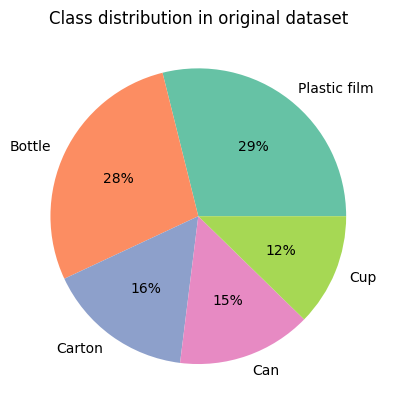

In [73]:
# Pie chart
piecolors = sns.color_palette('Set2',5)
plt.pie(c1_info.c1_label.value_counts(normalize=False), labels = c1_info.c1_label.value_counts(normalize=False).index, colors = piecolors, autopct='%.0f%%')
plt.title("Class distribution in original dataset")
plt.show()

In [84]:
import os
from PIL import Image

# Function to save images to folders
def save_images_to_folders(image_data, labels, destination_path,  prefix="image"):
    for i, (image, label) in enumerate(zip(image_data, labels)):
        label_folder = os.path.join(destination_path, str(label))  # Create a folder for each label
        os.makedirs(label_folder, exist_ok=True)
        
        # Convert the numpy array to an image
        #img = Image.fromarray((image * 255).astype('uint8'))
        img=Image.fromarray(image.astype(np.uint8))
        img.save(os.path.join(label_folder, f"{prefix}_{i}.png"))

# Path where images will be saved
destination_images_path = "processed_data\\features\classification_folder"

# Save images for task C1
save_images_to_folders(c1_images, c1_info["c1_label"], destination_images_path)

In [85]:
import os

# Function to display the number of images in each folder
def display_folder_image_counts(destination_path):
    for folder_name in os.listdir(destination_path):
        folder_path = os.path.join(destination_path, folder_name)
        if os.path.isdir(folder_path):
            num_images = len(os.listdir(folder_path))  # Count number of files in folder
            print(f"Folder '{folder_name}' contains {num_images} images")

# Display number of images in each folder
display_folder_image_counts(destination_images_path)

Folder 'Bottle' contains 438 images
Folder 'Can' contains 229 images
Folder 'Carton' contains 251 images
Folder 'Cup' contains 192 images
Folder 'Plastic film' contains 451 images


In [ ]:
import shutil

# Zip the classification folder
shutil.make_archive(destination_images_path, 'zip', destination_images_path)

# Download the zipped dataset
from IPython.display import FileLink

# Create a downloadable link for the zipped folder
FileLink(f"{destination_images_path}.zip")